In [55]:
import torch
from torchvision.datasets import CIFAR100
from torchvision import transforms

# 1. Tải tập train tạm thời chỉ với ToTensor() để tính mean/std trên miền [0.0, 1.0]
#raw_train_dataset = CIFAR100(root="data", train=True, download=True, transform=transforms.ToTensor())

# 2. Gom toàn bộ ảnh thành một tensor có hình dạng (N, C, H, W) -> (50000, 3, 32, 32)
#imgs = torch.stack([img for img, _ in raw_train_dataset], dim=0)

# 3. Tính Mean và Std theo các kênh R, G, B (dim=(0, 2, 3))
#pixel_mean = imgs.mean(dim=[0, 2, 3]).tolist()
#pixel_std = imgs.std(dim=[0, 2, 3]).tolist()
# Giá trị Mean và Std chuẩn của CIFAR-100 (trên miền [0, 1]) -->thuc nghiem cong dong
#CIFAR100_MEAN = [0.5071, 0.4867, 0.4408]
#CIFAR100_STD  = [0.2675, 0.2565, 0.2761]
# 1. BẮT BỘ THÔNG SỐ CHUẨN CỦA IMAGENET (Dành cho ResNet Pre-trained)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# 4. Tạo transform chính thức chua augmentation 
# dynamic_transform = transforms.Compose([
#     transforms.ToTensor(),
#     transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
# ])

# # 5. Khởi tạo Dataset chuẩn
# FINAL_TRAIN_DATASET = CIFAR100(root="data", train=True, download=True, transform=dynamic_transform)
# FINAL_TEST_DATASET  = CIFAR100(root="data", train=False, download=True, transform=dynamic_transform)

MÔ HÌNH RESNET-18 PRE-TRAINED

In [60]:
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị: {device}")

Đang sử dụng thiết bị: cuda


TRAINING & VALIDATION LOOP --BECOME--

In [67]:
import json
import os

def save_and_update_history_json(new_history, filepath="training_history.json"):
    """
    Lưu hoặc cập nhật thêm dữ liệu huấn luyện vào file JSON.
    
    Args:
        new_history (dict): Dictionary chứa dữ liệu các epoch mới train.
        filepath (str): Đường dẫn file JSON để lưu.
    """
    # Nếu file đã tồn tại, đọc dữ liệu cũ ra để nối tiếp
    if os.path.exists(filepath):
        with open(filepath, 'r', encoding='utf-8') as f:
            existing_history = json.load(f)
        
        # Cập nhật nối tiếp danh sách các chỉ số
        for key in new_history:
            if key in existing_history:
                existing_history[key].extend(new_history[key])
            else:
                existing_history[key] = new_history[key]
        
        data_to_save = existing_history
        print(f"--> Đã CẬP NHẬT nối tiếp dữ liệu vào file: '{filepath}'")
    else:
        data_to_save = new_history
        print(f"--> Đã TẠO MỚI và lưu dữ liệu vào file: '{filepath}'")

    # Ghi dữ liệu ra file JSON
    with open(filepath, 'w', encoding='utf-8') as f:
        json.dump(data_to_save, f, indent=4)
        
    return data_to_save

In [68]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR100
from torchvision import transforms, models

# 1. BẮT BỘ THÔNG SỐ CHUẨN CỦA IMAGENET (Dành cho ResNet Pre-trained)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# 2. Pipeline Transform cho Train (Có Augmentation + Resize 224x224)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# 3. Pipeline Transform cho Val & Test (CHỈ Resize + Normalize, KHÔNG Augmentation)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# 4. Khởi tạo Dataset chuẩn
raw_train_dataset  = CIFAR100(root="data", train=True, download=True, transform=train_transform)
raw_val_dataset    = CIFAR100(root="data", train=True, download=False, transform=test_transform)
final_test_dataset = CIFAR100(root="data", train=False, download=True, transform=test_transform)

# 5. Chia Train (90%) - Val (10%) từ 50,000 mẫu
total_samples = len(raw_train_dataset)
train_size = int(0.9 * total_samples)
val_size = total_samples - train_size

generator = torch.Generator().manual_seed(42)
permuted_indices = torch.randperm(total_samples, generator=generator).tolist()

train_indices = permuted_indices[:train_size]
val_indices   = permuted_indices[train_size:]

TRAIN_SUBSET = Subset(raw_train_dataset, train_indices)
VAL_SUBSET   = Subset(raw_val_dataset, val_indices)

# 6. DataLoader với num_workers=0 để tránh lỗi Shared Memory (shm)
BATCH_SIZE = 64
train_loader = DataLoader(TRAIN_SUBSET, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(VAL_SUBSET, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(final_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

# 7. Khởi tạo Mô hình Pre-trained & Thay đổi lớp fc
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 100)
model = model.to(device)

# 8. Cấu hình Optimizer với Learning Rate NHỎ (1e-4) để Fine-tune
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2) # lr=1e-4 thay vì 1e-3

In [69]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
        
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
    return running_loss / total, correct / total

# Chạy thử 10 Epochs
NUM_EPOCHS = 10
best_val_acc = 0.0
current_run_history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}
print("\n--- BẮT ĐẦU HUẤN LUYỆN ---")
for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc     = evaluate(model, val_loader, criterion, device)
    
    # Cập nhật Learning Rate Scheduler
    scheduler.step()
    # Cập nhật thông số từng epoch vào dict
    current_run_history['train_loss'].append(round(train_loss, 4))
    current_run_history['train_acc'].append(round(train_acc * 100, 2))
    current_run_history['val_loss'].append(round(val_loss, 4))
    current_run_history['val_acc'].append(round(val_acc * 100, 2))   
    # SỬA LỖI PRINT: Định dạng chuỗi f-string trên 1 dòng sạch sẽ và rõ ràng
    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")
    
    # Lưu checkpoint mô hình tốt nhất dựa trên Validation Accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_resnet18_cifar100.pth")
        print(f"  --> Đã lưu model mới tốt nhất với Val Acc: {val_acc*100:.2f}%")
# LƯU & CẬP NHẬT VÀO FILE JSON
full_history = save_and_update_history_json(current_run_history, filepath="resnet18_cifar100_history.json")
# ==========================================
# ĐÁNH GIÁ TRÊN TẬP TEST
# ==========================================
print("\n--- ĐÁNH GIÁ TRÊN TẬP TEST ---")
# Load lại trọng số tốt nhất đã lưu
model.load_state_dict(torch.load("best_resnet18_cifar100.pth"))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")


--- BẮT ĐẦU HUẤN LUYỆN ---
Epoch [01/10] | Train Loss: 1.7652 - Train Acc: 57.93% | Val Loss: 0.9801 - Val Acc: 72.12%
  --> Đã lưu model mới tốt nhất với Val Acc: 72.12%
Epoch [02/10] | Train Loss: 0.7836 - Train Acc: 78.44% | Val Loss: 0.7776 - Val Acc: 77.64%
  --> Đã lưu model mới tốt nhất với Val Acc: 77.64%
Epoch [03/10] | Train Loss: 0.5119 - Train Acc: 85.82% | Val Loss: 0.7178 - Val Acc: 78.76%
  --> Đã lưu model mới tốt nhất với Val Acc: 78.76%
Epoch [04/10] | Train Loss: 0.3480 - Train Acc: 90.40% | Val Loss: 0.7051 - Val Acc: 79.08%
  --> Đã lưu model mới tốt nhất với Val Acc: 79.08%
Epoch [05/10] | Train Loss: 0.2288 - Train Acc: 93.91% | Val Loss: 0.6788 - Val Acc: 80.06%
  --> Đã lưu model mới tốt nhất với Val Acc: 80.06%
Epoch [06/10] | Train Loss: 0.1593 - Train Acc: 95.94% | Val Loss: 0.6965 - Val Acc: 80.10%
  --> Đã lưu model mới tốt nhất với Val Acc: 80.10%
Epoch [07/10] | Train Loss: 0.1209 - Train Acc: 96.98% | Val Loss: 0.7499 - Val Acc: 78.86%
Epoch [08/10] | 

--> Đã CẬP NHẬT nối tiếp dữ liệu vào file: 'resnet18_cifar100_history.json'

--- ĐÁNH GIÁ TRÊN TẬP TEST (BEST CHECKPOINT) ---
--> Test Loss     : 0.7341
--> Test Accuracy : 80.07%



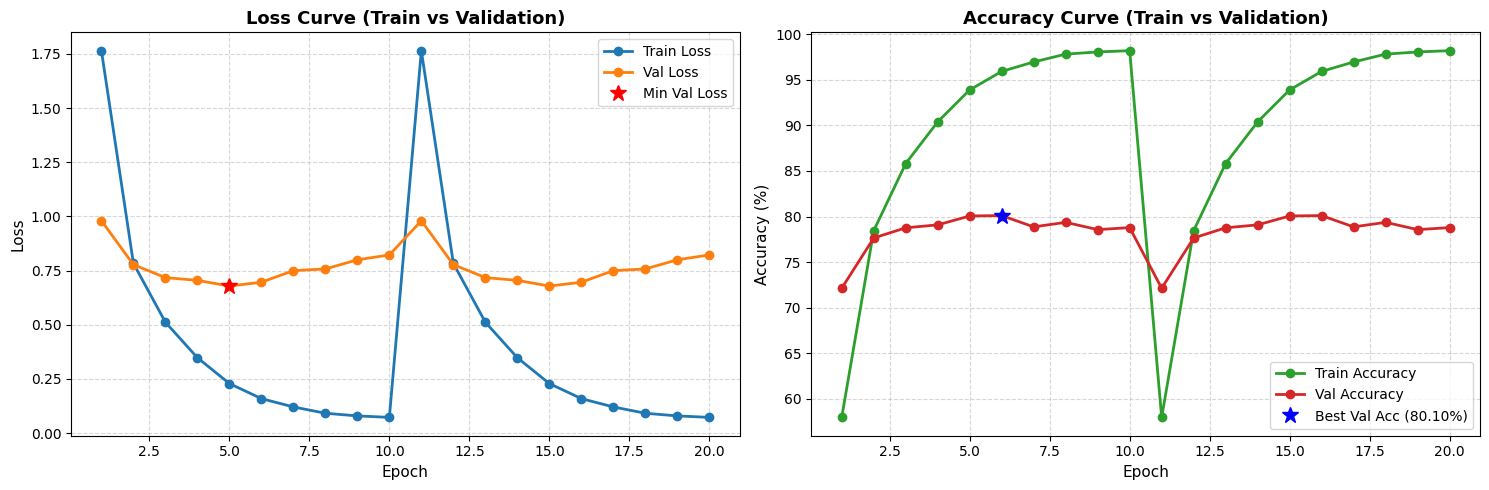

In [70]:
import torch
import json
import os
import matplotlib.pyplot as plt

# ==========================================
# HÀM VẼ ĐỒ THỊ LOSS & ACCURACY
# ==========================================
def plot_training_results(history_filepath="resnet18_cifar100_history.json"):
    """
    Đọc dữ liệu từ file JSON và vẽ đồ thị so sánh Train/Val Loss và Accuracy.
    """
    if not os.path.exists(history_filepath):
        print(f"Không tìm thấy file '{history_filepath}' để vẽ đồ thị.")
        return

    with open(history_filepath, 'r', encoding='utf-8') as f:
        history = json.load(f)

    epochs = range(1, len(history['train_loss']) + 1)
    
    # Khởi tạo giao diện đồ thị
    plt.figure(figsize=(15, 5))
    
    # Biểu đồ 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'o-', color='#1f77b4', label='Train Loss', linewidth=2)
    plt.plot(epochs, history['val_loss'], 'o-', color='#ff7f0e', label='Val Loss', linewidth=2)
    
    # Đánh dấu điểm Val Loss nhỏ nhất
    min_val_loss_idx = history['val_loss'].index(min(history['val_loss']))
    plt.plot(min_val_loss_idx + 1, history['val_loss'][min_val_loss_idx], 'r*', markersize=12, label='Min Val Loss')
    
    plt.title('Loss Curve (Train vs Validation)', fontsize=13, fontweight='bold')
    plt.xlabel('Epoch', fontsize=11)
    plt.ylabel('Loss', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)

    # Biểu đồ 2: Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], 'o-', color='#2ca02c', label='Train Accuracy', linewidth=2)
    plt.plot(epochs, history['val_acc'], 'o-', color='#d62728', label='Val Accuracy', linewidth=2)
    
    # Đánh dấu điểm Val Acc cao nhất
    max_val_acc_idx = history['val_acc'].index(max(history['val_acc']))
    plt.plot(max_val_acc_idx + 1, history['val_acc'][max_val_acc_idx], 'b*', markersize=12, label=f'Best Val Acc ({max(history["val_acc"]):.2f}%)')

    plt.title('Accuracy Curve (Train vs Validation)', fontsize=13, fontweight='bold')
    plt.xlabel('Epoch', fontsize=11)
    plt.ylabel('Accuracy (%)', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()


# ==========================================
# HỰC THI LƯU THÔNG SỐ, ĐÁNH GIÁ TEST & VẼ HÌNH
# ==========================================

# 1. Cập nhật lịch sử của lượt train hiện tại vào JSON
full_history = save_and_update_history_json(current_run_history, filepath="resnet18_cifar100_history.json")

# 2. Tải checkpoint tốt nhất và đánh giá trên tập TEST
print("\n" + "="*50)
print("--- ĐÁNH GIÁ TRÊN TẬP TEST (BEST CHECKPOINT) ---")
print("="*50)

model.load_state_dict(torch.load("best_resnet18_cifar100.pth"))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)

print(f"--> Test Loss     : {test_loss:.4f}")
print(f"--> Test Accuracy : {test_acc * 100:.2f}%")
print("="*50 + "\n")

# 3. Vẽ đồ thị trực quan hóa kết quả
plot_training_results("resnet18_cifar100_history.json")

In [71]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def get_all_preds(model, dataloader, device):
    """
    Trích xuất toàn bộ nhãn thực tế (true labels) và nhãn dự đoán (predictions) trên tập data.
    """
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    return np.array(all_labels), np.array(all_preds)

# 1. Nạp checkpoint tốt nhất (đạt 80.10% Val Acc ở Epoch 6)[cite: 1]
model.load_state_dict(torch.load("best_resnet18_cifar100.pth"))

# 2. Lấy danh sách dự đoán trên tập Test
y_true, y_pred = get_all_preds(model, test_loader, device)
class_names = final_test_dataset.classes  # Danh sách 100 tên lớp của CIFAR-100

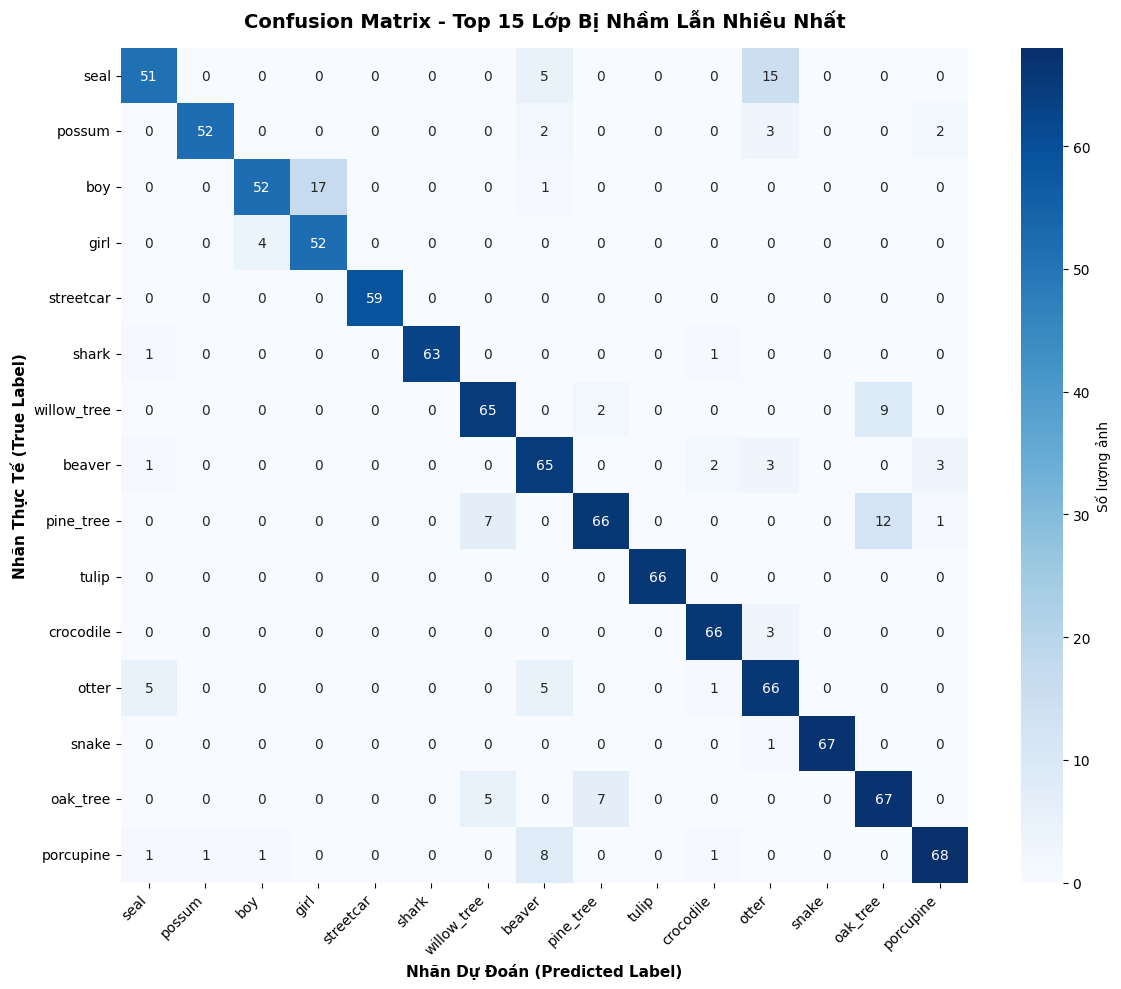

In [72]:
def plot_top_confused_classes(y_true, y_pred, class_names, top_n=15):
    """
    Tính Confusion Matrix và vẽ Seaborn Heatmap cho Top N lớp có số lượng dự đoán sai nhiều nhất.
    """
    # Tính Confusion Matrix tổng thể 100x100
    cm_full = confusion_matrix(y_true, y_pred)
    
    # Tính tổng số mẫu dự đoán sai cho từng lớp (Tổng hàng - Phần tử trên đường chéo chính)
    errors_per_class = cm_full.sum(axis=1) - np.diag(cm_full)
    
    # Lấy chỉ số N lớp có số mẫu sai nhiều nhất
    top_error_indices = np.argsort(errors_per_class)[::-1][:top_n]
    
    # Trích xuất sub-matrix cho N lớp này
    cm_sub = cm_full[np.ix_(top_error_indices, top_error_indices)]
    top_class_names = [class_names[i] for i in top_error_indices]
    
    # Vẽ Heatmap bằng Seaborn
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm_sub, 
        annot=True, 
        fmt='d', 
        cmap='Blues',
        xticklabels=top_class_names,
        yticklabels=top_class_names,
        cbar_kws={'label': 'Số lượng ảnh'}
    )
    
    plt.title(f'Confusion Matrix - Top {top_n} Lớp Bị Nhầm Lẫn Nhiều Nhất', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11, fontweight='bold')
    plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=11, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Gọi hàm vẽ biểu đồ cho Top 15 lớp nhầm lẫn nhiều nhất
plot_top_confused_classes(y_true, y_pred, class_names, top_n=15)

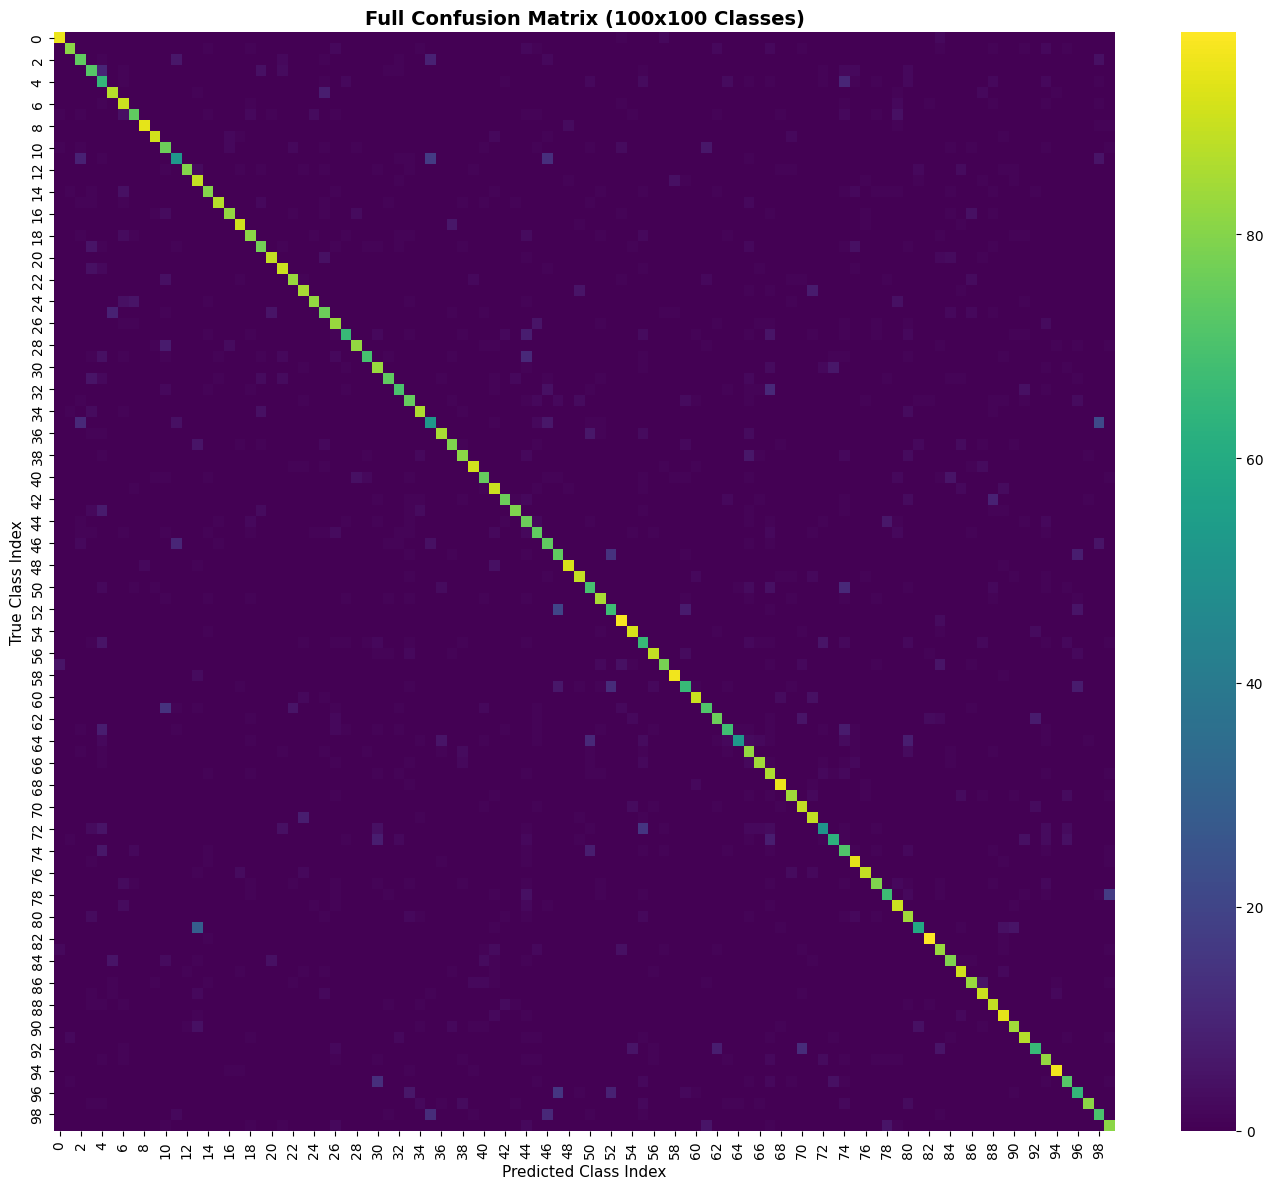

In [73]:
def plot_full_confusion_matrix(y_true, y_pred):
    cm_full = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(14, 12))
    sns.heatmap(cm_full, cmap='viridis', cbar=True)
    plt.title('Full Confusion Matrix (100x100 Classes)', fontsize=14, fontweight='bold')
    plt.xlabel('Predicted Class Index', fontsize=11)
    plt.ylabel('True Class Index', fontsize=11)
    plt.tight_layout()
    plt.show()

plot_full_confusion_matrix(y_true, y_pred)